# Phase 7.1 - Detector Online 1D (YOLO-like) + Progresion

Objetivo de esta fase:
- Construir detector online sobre ventana rodante de **256 barras**.
- Tarea multitarea:
  1. **Aislar**: `class_id=0` (desconocido/ruido).
  2. **Clasificar**: clase de patron conocido.
  3. **Progresion**: porcentaje de completitud del patron (`0..1`).

Implementacion de referencia:
- Dataset desde `phase4` (`GBPUSD_segments_long + cluster_assignments`).
- Modelo 1D CNN multitarea (clasificacion + regresion).

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path('.')

# Ejecutar pipeline completo (dataset + training + eval)
import importlib.util
script_path = ROOT / 'phases/phase07_online_detector/run_phase7_online_detector_v1.py'
spec = importlib.util.spec_from_file_location('run_phase7_online_detector_v1', script_path)
mod = importlib.util.module_from_spec(spec)
spec.loader.exec_module(mod)
summary, test_df, cm_df, history_df = mod.main()

OUT_DIR = ROOT / 'phases/phase07_online_detector/output_online_detector_GBPUSD_v1'
SUMMARY_JSON = OUT_DIR / 'GBPUSD_online_detector_summary_v1.json'
HISTORY_CSV = OUT_DIR / 'GBPUSD_online_train_history_v1.csv'
PRED_CSV = OUT_DIR / 'GBPUSD_online_test_predictions_v1.csv'
CM_CSV = OUT_DIR / 'GBPUSD_online_confusion_matrix_v1.csv'
BARS_PQ = OUT_DIR / 'GBPUSD_online_bars_labeled_v1.parquet'

summary = json.loads(SUMMARY_JSON.read_text())
history = pd.read_csv(HISTORY_CSV)
preds = pd.read_csv(PRED_CSV)
cm = pd.read_csv(CM_CSV, index_col=0)
bars = pd.read_parquet(BARS_PQ)

print('summary ->', SUMMARY_JSON)
print('history ->', HISTORY_CSV)
print('preds ->', PRED_CSV)
print('confusion ->', CM_CSV)

Saved summary: ./phases/phase07_online_detector/output_online_detector_GBPUSD_v1/GBPUSD_online_detector_summary_v1.json
Test metrics: {'loss': 1.2666700236937578, 'acc': 0.5403624382207578, 'f1_macro_known': 0.1997912522893322, 'recall_unknown': 0.5938890536932661, 'mae_progress_known': 0.2629138231277466}
summary -> ./phases/phase07_online_detector/output_online_detector_GBPUSD_v1/GBPUSD_online_detector_summary_v1.json
history -> ./phases/phase07_online_detector/output_online_detector_GBPUSD_v1/GBPUSD_online_train_history_v1.csv
preds -> ./phases/phase07_online_detector/output_online_detector_GBPUSD_v1/GBPUSD_online_test_predictions_v1.csv
confusion -> ./phases/phase07_online_detector/output_online_detector_GBPUSD_v1/GBPUSD_online_confusion_matrix_v1.csv


In [2]:
pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 220)

print('Config principal:')
print('window_bars =', summary['window_bars'])
print('n_classes =', summary['dataset']['n_classes_total_including_0'])
print('cluster_to_class =', summary['class_mapping_cluster_to_class'])
print('dataset sizes =', summary['dataset'])
print('\nMetrics test:')
print(summary['metrics_test'])
print('\nMetrics val:')
print(summary['metrics_val'])

Config principal:
window_bars = 256
n_classes = 3
cluster_to_class = {'4': 1, '9': 2}
dataset sizes = {'n_bars_labeled': 30023, 'n_windows_total': 29258, 'n_windows_train': 20761, 'n_windows_val': 4248, 'n_windows_test': 4249, 'n_classes_total_including_0': 3}

Metrics test:
{'loss': 1.2666700236937578, 'acc': 0.5403624382207578, 'f1_macro_known': 0.1997912522893322, 'recall_unknown': 0.5938890536932661, 'mae_progress_known': 0.2629138231277466}

Metrics val:
{'loss': 1.1700879686019, 'acc': 0.4044256120527307, 'f1_macro_known': 0.20949476341901052, 'recall_unknown': 0.39975772259236825, 'mae_progress_known': 0.260941743850708}


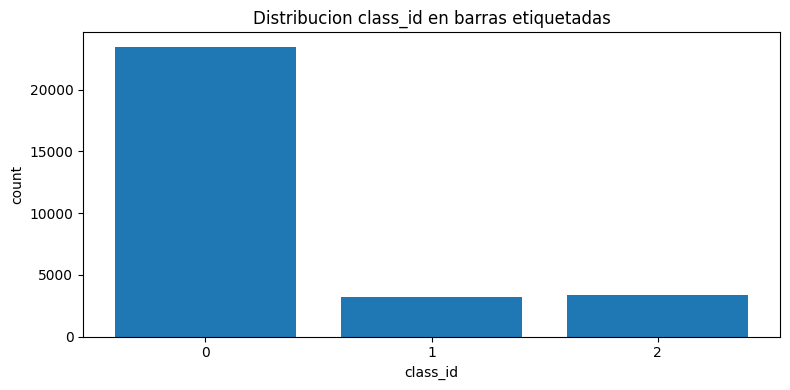

,count
class_id,
0,23481
1,3186
2,3356


In [3]:
# Distribucion de clases en barras etiquetadas
class_counts = bars['class_id'].value_counts().sort_index()

plt.figure(figsize=(8,4))
plt.bar(class_counts.index.astype(str), class_counts.values)
plt.title('Distribucion class_id en barras etiquetadas')
plt.xlabel('class_id')
plt.ylabel('count')
plt.tight_layout()
plt.show()

display(class_counts.to_frame('count'))

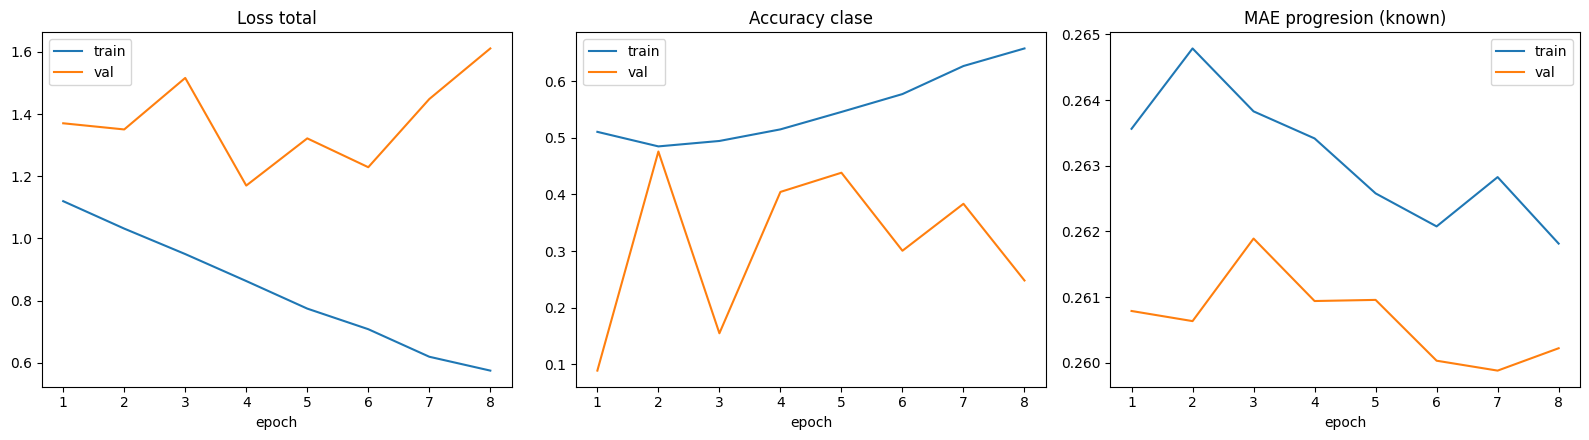

,epoch,lr,train_loss,train_loss_cls,train_loss_prog,train_acc,train_f1_macro_known,train_recall_unknown,train_mae_prog_known,val_loss,val_loss_cls,val_loss_prog,val_acc,val_f1_macro_known,val_recall_unknown,val_mae_prog_known
0,1,0.00100,1.119933,1.064141,0.092987,0.510476,0.224615,0.555266,0.263562,1.370351,1.314652,0.092832,0.088983,0.074923,0.011508,0.260790
1,2,0.00100,1.031765,0.975773,0.093320,0.484803,0.301310,0.468566,0.264785,1.350552,1.294953,0.092664,0.475753,0.062622,0.572380,0.260636
2,3,0.00100,0.949902,0.894405,0.092495,0.494389,0.342391,0.455285,0.263827,1.516156,1.460086,0.093451,0.154896,0.126224,0.015748,0.261892
3,4,0.00100,0.863176,0.807937,0.092064,0.514860,0.382853,0.458512,0.263416,1.170088,1.114549,0.092565,0.404426,0.209495,0.399758,0.260942
4,5,0.00100,0.774556,0.719097,0.092432,0.545638,0.422269,0.480047,0.262580,1.321836,1.266089,0.092910,0.438324,0.271779,0.428225,0.260959
5,6,0.00050,0.708342,0.652798,0.092574,0.577188,0.451816,0.511326,0.262077,1.229112,1.173896,0.092026,0.300612,0.245161,0.206844,0.260034
6,7,0.00050,0.619773,0.564403,0.092282,0.626704,0.501610,0.559486,0.262827,1.448276,1.393074,0.092004,0.383475,0.199199,0.333737,0.259883
7,8,0.00025,0.575201,0.519830,0.092285,0.657724,0.529733,0.594117,0.261816,1.610971,1.555625,0.092244,0.248117,0.205265,0.134161,0.260223


In [4]:
# Curvas de entrenamiento
fig, axes = plt.subplots(1, 3, figsize=(16,4.5))

axes[0].plot(history['epoch'], history['train_loss'], label='train')
axes[0].plot(history['epoch'], history['val_loss'], label='val')
axes[0].set_title('Loss total')
axes[0].set_xlabel('epoch')
axes[0].legend()

axes[1].plot(history['epoch'], history['train_acc'], label='train')
axes[1].plot(history['epoch'], history['val_acc'], label='val')
axes[1].set_title('Accuracy clase')
axes[1].set_xlabel('epoch')
axes[1].legend()

axes[2].plot(history['epoch'], history['train_mae_prog_known'], label='train')
axes[2].plot(history['epoch'], history['val_mae_prog_known'], label='val')
axes[2].set_title('MAE progresion (known)')
axes[2].set_xlabel('epoch')
axes[2].legend()

plt.tight_layout()
plt.show()

display(history)

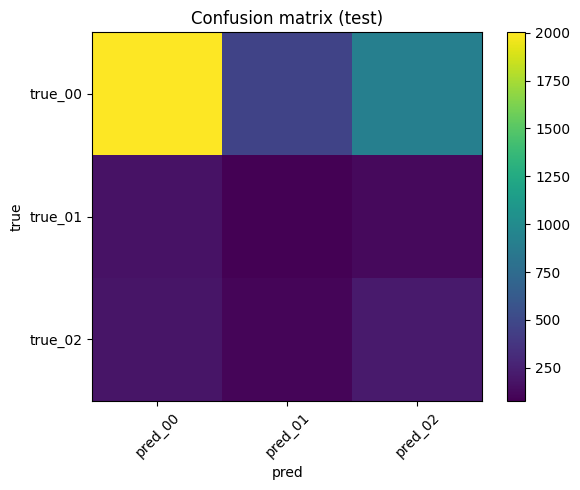

,pred_00,pred_01,pred_02
true_00,2002,463,906
true_01,173,77,124
true_02,186,101,217


In [5]:
# Matriz de confusion
plt.figure(figsize=(6,5))
plt.imshow(cm.values, aspect='auto')
plt.title('Confusion matrix (test)')
plt.xlabel('pred')
plt.ylabel('true')
plt.colorbar()
plt.xticks(range(len(cm.columns)), cm.columns, rotation=45)
plt.yticks(range(len(cm.index)), cm.index)
plt.tight_layout()
plt.show()

display(cm)

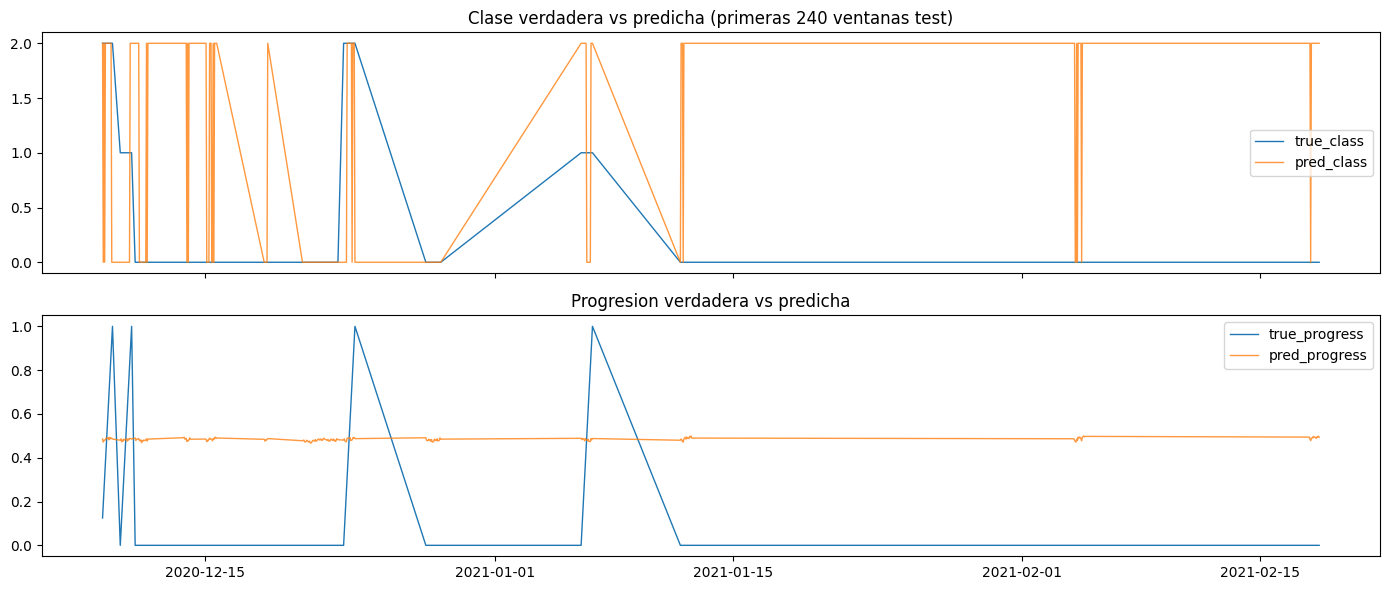

,end_ts,true_class_id,pred_class_id,true_progress,pred_progress,known_mask,ok_cls
0,2020-12-08 23:00:00,2,2,0.1250,0.485986,1,1
1,2020-12-09 00:00:00,2,0,0.1875,0.471885,1,0
2,2020-12-09 01:00:00,2,2,0.2500,0.479517,1,1
3,2020-12-09 02:00:00,2,0,0.3125,0.479565,1,0
4,2020-12-09 03:00:00,2,2,0.3750,0.483418,1,1
5,2020-12-09 04:00:00,2,2,0.4375,0.489630,1,1
6,2020-12-09 05:00:00,2,2,0.5000,0.487989,1,1
7,2020-12-09 06:00:00,2,2,0.5625,0.488736,1,1
8,2020-12-09 07:00:00,2,2,0.6250,0.491992,1,1
9,2020-12-09 08:00:00,2,2,0.6875,0.481822,1,1


In [6]:
# Ejemplo temporal: prediccion de clase y progresion (subset test)
preds['end_ts'] = pd.to_datetime(preds['end_ts'])
sub = preds.sort_values('end_ts').head(240).copy()

fig, axes = plt.subplots(2,1, figsize=(14,6), sharex=True)
axes[0].plot(sub['end_ts'], sub['true_class_id'], label='true_class', linewidth=1)
axes[0].plot(sub['end_ts'], sub['pred_class_id'], label='pred_class', linewidth=1, alpha=0.8)
axes[0].set_title('Clase verdadera vs predicha (primeras 240 ventanas test)')
axes[0].legend()

axes[1].plot(sub['end_ts'], sub['true_progress'], label='true_progress', linewidth=1)
axes[1].plot(sub['end_ts'], sub['pred_progress'], label='pred_progress', linewidth=1, alpha=0.8)
axes[1].set_title('Progresion verdadera vs predicha')
axes[1].legend()

plt.tight_layout()
plt.show()

display(preds.head(20))